# Task 1 — Predicciones, equilibrio y línea base (Entrega parcial)
Grupo 5 — q = 0.20, D = 3 días. CC2017 Modelación y Simulación.

* **1.1** Las predicciones están en `predicciones/task1_1_predicciones.md` y se commitearon **antes** de simular (no se modifican).
* **1.2** Equilibrio del lazo con capacidad fija (c = 4, sin rechazos), calculado a mano y resuelto numéricamente.
* **1.3** Línea base generada por una IA (se ejecuta sin modificar; ver sección al final).

In [1]:
import sys, pathlib, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

ROOT = pathlib.Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from des import mmc_teoria
from sd import Params, rhs, delta, umbral_U
from hibrido import simular_hibrido

FIG, RES = ROOT / 'figuras', ROOT / 'resultados'
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
P = Params()
C_FIJO = 4
print(open(ROOT / 'predicciones' / 'task1_1_predicciones.md', encoding='utf-8').read())

# Task 1.1 — Predicciones (grupo 5: q = 0.20, D = 3 días)

Con g = 5: (5−1) mod 4 = 0, así que q = 0.20 y D = 3 días.

a. Retroalimentación completa vs. cascada

U(100): menor con el lazo cerrado, aunque la diferencia debería ser pequeña (estimamos entre 2% y 8% menos). Con el lazo cerrado, la latencia alta antes de que lleguen servidores provoca abandono y frena el crecimiento. Cuando llegan los servidores, la latencia baja y la plataforma se recupera casi por completo.
Latencia máxima: menor con el lazo cerrado. En la cascada los usuarios siguen creciendo aunque la cola esté saturada. En el lazo, el abandono reduce la carga, así que funciona como un freno natural.
Fracción máxima rechazada: cercana a 0 en ambos casos, un poco menor en el lazo. Con K = 60 y ρ < 1 la cola casi nunca se llena; el riesgo solo existe si U pasa de 16,000 con c = 4.

b. Primer pedido y servidores al día 100

El umbral con c = 4 es aU/8 = 0.7, es decir U ≈ 11,200. Con crecimiento tipo Bass a una tasa efectiv

## Task 1.2 — Equilibrio del lazo con capacidad fija (c = 4, sin rechazos)

### 1.2a — Latencia de la fila M/M/c en función de U
Carga ofrecida A = aU/μ. Con c servidores, la probabilidad de esperar es Erlang C:

C(c, A) = [A^c/c! · c/(c − A)] / [ Σ_{k=0}^{c−1} A^k/k! + A^c/c! · c/(c − A) ]

y la latencia W(U) = C(c, A)/(cμ − aU) + 1/μ. Es válida solo en régimen estable, **aU < cμ**, es decir
**U < cμ/a = 4·2/0.0005 = 16 000 usuarios**; a la izquierda de ese valor ρ = aU/(cμ) < 1, y W → ∞ cuando U → 16 000.

In [2]:
mu, a = P.mu, P.a
U_MAX_VALIDO = C_FIJO * mu / a
def W_c4(U):
    """W(U) = C(c,A)/(c mu - a U) + 1/mu  (M/M/c, c = 4); válida para a U < c mu."""
    return mmc_teoria(a * U, C_FIJO, mu)['W']
print(f'Rango de validez: 0 <= U < {U_MAX_VALIDO:.0f} usuarios')
tabla_W = pd.DataFrame([{'U': U, 'ρ = aU/(cμ)': a * U / (C_FIJO * mu), 'A = aU/μ': a * U / mu,
                         'Erlang C': mmc_teoria(a * U, C_FIJO, mu)['C'], 'W(U) (s)': W_c4(U)}
                        for U in [100, 4000, 8000, 11200, 12000, 12500, 13000, 14000, 15000, 15900]])
tabla_W.to_csv(RES / 'tabla_1_2a_W_de_U.csv', index=False)
tabla_W.round(4)

Rango de validez: 0 <= U < 16000 usuarios


,U,ρ = aU/(cμ),A = aU/μ,Erlang C,W(U) (s)
0,100,0.0062,0.025,0.0000,0.5000
1,4000,0.2500,1.000,0.0204,0.5034
2,8000,0.5000,2.000,0.1739,0.5435
3,11200,0.7000,2.800,0.4287,0.6786
4,12000,0.7500,3.000,0.5094,0.7547
5,12500,0.7812,3.125,0.5631,0.8218
6,13000,0.8125,3.250,0.6191,0.9127
7,14000,0.8750,3.500,0.7379,1.2379
8,15000,0.9375,3.750,0.8650,2.2301
9,15900,0.9938,3.975,0.9862,20.2234


### 1.2b — Ecuación de equilibrio y su solución numérica
Con c fijo y r = 0, δ(U) = δ₀ + κ_W·max(0, W(U) − W_ok). El equilibrio U* cumple dU/dt = 0, es decir,
**adopción neta = abandono**:

(p + q·U/M)(M − U) = [δ₀ + κ_W·max(0, W(U) − W_ok)]·U

Se define g(U) = adopción − abandono, se busca con una malla en (0, 16 000) cada cambio de signo y se refina con `brentq`.

In [3]:
def adopcion(U):  return (P.p + P.q * U / P.M) * (P.M - U)
def abandono(U):  return (P.delta0 + P.kW * max(0.0, W_c4(U) - P.Wok)) * U     # r = 0
g = lambda U: adopcion(U) - abandono(U)

malla = np.linspace(1.0, U_MAX_VALIDO - 1e-3, 4000)
gv = np.array([g(u) for u in malla])
cambios = np.where(np.sign(gv[:-1]) != np.sign(gv[1:]))[0]
raices = [brentq(g, malla[i], malla[i + 1], xtol=1e-10) for i in cambios]
print('Raíces de g(U) = 0 en (0, 16000):', [round(r, 3) for r in raices])
Ustar = raices[0]
eq = mmc_teoria(a * Ustar, C_FIJO, mu)
rho_star, W_star = eq['rho'], eq['W']
print(f'U* = {Ustar:.2f} usuarios | ρ* = {rho_star:.4f} | W* = {W_star:.4f} s | δ* = {P.delta0 + P.kW*(W_star-P.Wok):.4f} /día')
print(f'Comprobación g(U*) = {g(Ustar):.2e};  adopción = {adopcion(Ustar):.2f}, abandono = {abandono(Ustar):.2f} usuarios/día')

# Referencia sin retroalimentación (δ = δ0): equilibrio de la cascada
U_casc = brentq(lambda U: adopcion(U) - P.delta0 * U, 1.0, P.M - 1e-6)
print(f'Sin retroalimentación (δ = δ0): U = {U_casc:.1f}  (techo M = {P.M:.0f}; cμ/a = {U_MAX_VALIDO:.0f})')
pd.DataFrame([{'U*': Ustar, 'ρ*': rho_star, 'W* (s)': W_star, 'Wok (s)': P.Wok,
               'adopción en U* (usuarios/día)': adopcion(Ustar), 'U cascada (δ=δ0)': U_casc}]).to_csv(RES / 'tabla_1_2b_equilibrio.csv', index=False)

Raíces de g(U) = 0 en (0, 16000): [12508.642]
U* = 12508.64 usuarios | ρ* = 0.7818 | W* = 0.8231 s | δ* = 0.0761 /día
Comprobación g(U*) = 2.05e-12;  adopción = 952.05, abandono = 952.05 usuarios/día
Sin retroalimentación (δ = δ0): U = 19703.0  (techo M = 20000; cμ/a = 16000)


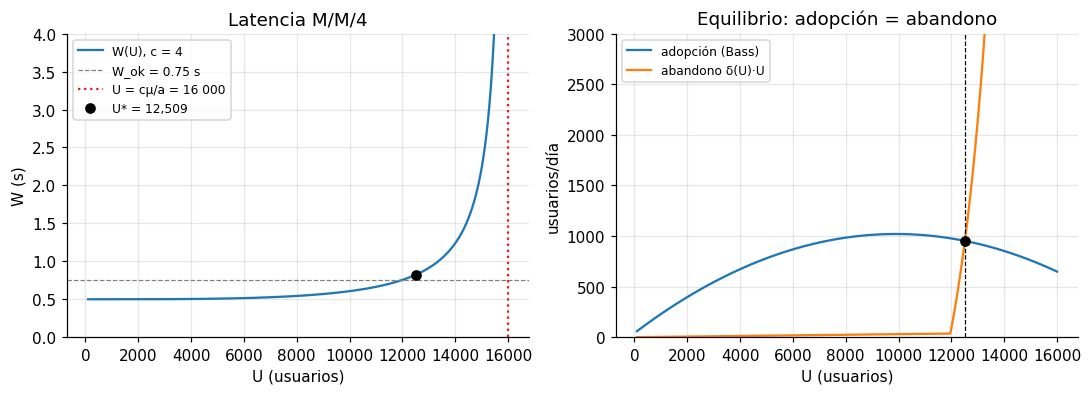

In [4]:
Ug = np.linspace(100, U_MAX_VALIDO - 5, 800)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
ax[0].plot(Ug, [W_c4(u) for u in Ug], label='W(U), c = 4')
ax[0].axhline(P.Wok, color='gray', ls='--', lw=.8, label='W_ok = 0.75 s')
ax[0].axvline(U_MAX_VALIDO, color='C3', ls=':', label='U = cμ/a = 16 000')
ax[0].plot([Ustar], [W_star], 'ko', label=f'U* = {Ustar:,.0f}')
ax[0].set_ylim(0, 4); ax[0].set_xlabel('U (usuarios)'); ax[0].set_ylabel('W (s)'); ax[0].set_title('Latencia M/M/4'); ax[0].legend(fontsize=8)
Ua = np.linspace(100, U_MAX_VALIDO - 5, 800)
ax[1].plot(Ua, [adopcion(u) for u in Ua], label='adopción (Bass)')
ax[1].plot(Ua, [abandono(u) for u in Ua], label='abandono δ(U)·U')
ax[1].axvline(Ustar, color='k', ls='--', lw=.8); ax[1].plot([Ustar], [adopcion(Ustar)], 'ko')
ax[1].set_ylim(0, 3000); ax[1].set_xlabel('U (usuarios)'); ax[1].set_ylabel('usuarios/día'); ax[1].set_title('Equilibrio: adopción = abandono'); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig_1_2_equilibrio_capacidad_fija.png', bbox_inches='tight'); plt.show()

### Verificación con el híbrido completo (c fija = 4, sin autoescalado)
Se simula el híbrido con θ muy alto para que nunca se emita un pedido: debe converger cerca de U*.

In [5]:
fijo = [simular_hibrido(P.con(theta=1e9), modo='evento', seed=500 + s) for s in range(10)]
U100_fijo = np.array([r['U_final'] for r in fijo])
print(f'Híbrido con c = 4 fija, 10 semillas: U(100) = {U100_fijo.mean():.1f} ± {U100_fijo.std(ddof=1):.1f}  vs  U* = {Ustar:.1f}')
print('Último W intercambiado (media):', np.mean([r['ex_W'][-1] for r in fijo]).round(4), '| W* teórico:', round(W_star, 4))

Híbrido con c = 4 fija, 10 semillas: U(100) = 12311.1 ± 852.3  vs  U* = 12508.6
Último W intercambiado (media): 0.7981 | W* teórico: 0.8231


**Interpretación 1.2b.** La ecuación tiene una sola raíz en (0, 16 000): **U\* = 12 508.6 usuarios**, con ρ\* = 0.782 y W\* = 0.823 s (> W_ok = 0.75 s). En ese punto adopción y abandono valen 952 usuarios/día. El híbrido con c = 4 fija termina en 12 311 ± 852 usuarios (10 semillas), coherente con U\*; la dispersión viene del ruido del DES, porque W y r cambian cada día.

## Contraste con las predicciones del Task 1.1 (no se modifican)
El híbrido completo (c(0) = 4, H = 1, 100 días, 20 semillas) con retroalimentación (lazo cerrado) y sin ella (cascada, κ_W = κ_R = 0), con las mismas semillas.

In [6]:
filas = []
for lazo in (True, False):
    for s in range(20):
        R = simular_hibrido(P, modo='evento', lazo=lazo, seed=700 + s)
        filas.append({'modelo': 'lazo cerrado' if lazo else 'cascada', 'semilla': s, 'U(100)': R['U_final'],
                      'W máx (s)': R['W_max'], 'r máx': R['r_max'], 'día 1.er pedido': R['t_pedido1'],
                      'día llegada 1': R['t_llegada1'], 'día 2.º pedido': R['pedidos'][1][0] if len(R['pedidos']) > 1 else np.nan,
                      'servidores día 100': R['c_final']})
cmp_ = pd.DataFrame(filas)
res_cmp = cmp_.drop(columns='semilla').groupby('modelo').agg(['mean', 'std'])
res_cmp.to_csv(RES / 'tabla_1_1_contraste_lazo_vs_cascada.csv')
dif_U = 100 * (cmp_[cmp_.modelo == 'lazo cerrado']['U(100)'].mean() / cmp_[cmp_.modelo == 'cascada']['U(100)'].mean() - 1)
print(f'U(100) lazo vs cascada: {dif_U:+.4f} %   (predicción 1.1a: entre −2 % y −8 %)')
res_cmp.round(4).T

U(100) lazo vs cascada: -0.0000 %   (predicción 1.1a: entre −2 % y −8 %)


modelo                      cascada  lazo cerrado
U(100)             mean  19703.0117    19703.0095
                   std       0.0000        0.0012
W máx (s)          mean      1.0806        0.9182
                   std       0.1459        0.1010
r máx              mean      0.0000        0.0000
                   std       0.0000        0.0000
día 1.er pedido    mean     22.4209       22.4209
                   std       0.0000        0.0000
día llegada 1      mean     25.4209       25.4209
                   std       0.0000        0.0000
día 2.º pedido     mean     29.8266       32.5628
                   std       0.0000        1.0869
servidores día 100 mean      8.0000        8.0000
                   std       0.0000        0.0000

**Interpretación 1.2c (tres líneas).**
1. Con c = 4 la capacidad es cμ/a = 16 000 usuarios y W(U) → ∞ al acercarse; el abandono δ(U)·U crece con W mientras la adopción de Bass cae a 0 en M, así que se cruzan en U\* = 12 509, antes de 16 000 y de M = 20 000.
2. Sin retroalimentación el sistema iría a 19 703 usuarios (ρ = 1.23), por encima de la capacidad; con ella, el lazo se autolimita en un punto estable con ρ < 1 y sin rechazos.
3. La retroalimentación hace de freno: cuando la latencia sube, los usuarios abandonan, baja la carga y baja la latencia; el equilibrio es el punto donde ese freno compensa exactamente la adopción.

**Contraste con 1.1a (sin cambiar la predicción).** Dirección y ρ < 1 coinciden con lo predicho (el lazo frena y la cola no se llena), pero con capacidad fija el freno es mucho mayor que el 2–8 % estimado (U\* queda 36.5 % bajo la cascada). Con autoescalado, en cambio, el resultado es otro: U(100) es **igual** con y sin lazo (19 703; diferencia 0.0000 %, no −2 % a −8 %), porque los servidores llegan antes de que el freno modifique la trayectoria de forma sostenida. La latencia máxima sí es menor con lazo (0.92 vs 1.08 s) y el rechazo máximo es 0 en ambos. Para 1.1b, el primer pedido sale el día 22.4 (predijimos 26–30) y el segundo el día 32.6 con lazo y 29.8 en cascada (predijimos 40–50); los servidores finales sí son 8. Estas diferencias quedan como material para el Task 3.1c.

## Task 1.3 — Línea base generada por una IA
El prompt, el código y la respuesta de la IA están **sin modificar** en `anexo_linea_base_IA/` (commit `1486bae`). Aquí se ejecuta el código tal cual (H = 1 día, c(0) = 4, 100 días, semilla 42 que la propia IA fija) y se contrastan sus afirmaciones con una verificación independiente.

### 1.3b — Ejecución sin cambios

In [7]:
import importlib.util
spec = importlib.util.spec_from_file_location('ia', ROOT / 'anexo_linea_base_IA' / 'codigo_original.py')
ia = importlib.util.module_from_spec(spec); spec.loader.exec_module(ia)   # el bloque __main__ no se ejecuta
assert ia.H == 1.0 and ia.c0 == 4 and ia.T_FINAL == 100.0
r_ia = ia.simular(seed=42)
t1 = pd.DataFrame([{'U(100)': r_ia['U'][-1], 'servidores finales': int(r_ia['c'][-1]),
                    'latencia máxima W (s)': r_ia['W'].max(), 'rechazo máximo r': r_ia['r'].max(),
                    'pedidos (día)': str([round(x, 2) for x in r_ia['pedidos']]),
                    'entregas (día)': str([round(x, 2) for x in r_ia['entregas']])}])
t1.to_csv(RES / 'tabla_1_3b_linea_base_ejecucion.csv', index=False)
reps = pd.DataFrame([{'semilla': s, 'U(100)': (x := ia.simular(seed=s))['U'][-1], 'c final': int(x['c'][-1]),
                      'W máx': x['W'].max(), 'r máx': x['r'].max()} for s in range(10)])
reps.to_csv(RES / 'tabla_1_3b_linea_base_10_semillas.csv', index=False)
display(t1.round(4).T)
print(reps.describe().loc[['mean', 'min', 'max']].round(3))

,0
U(100),19703.0098
servidores finales,8
latencia máxima W (s),0.8456
rechazo máximo r,0.0
pedidos (día),"[22.44, 32.4]"
entregas (día),"[25.44, 35.4]"


      semilla     U(100)  c final  W máx  r máx
mean      4.5  19703.009      8.0  0.958    0.0
min       0.0  19703.008      8.0  0.820    0.0
max       9.0  19703.011      8.0  1.078    0.0


### 1.3c — Afirmaciones de la IA y qué verificamos
Se verifica cada afirmación con las funciones propias de `src/` (Erlang C, M/M/c/K exacto, nuestro híbrido con RK4 y evento localizado) y con el propio resultado de la IA.

In [8]:
a_, mu_ = P.a, P.mu
# (1) equilibrio de U con delta = delta0
U_eq = brentq(lambda U: rhs(U, P, delta=P.delta0) if False else (P.p + P.q * U / P.M) * (P.M - U) - P.delta0 * U, 1, P.M)
aprox = 0.202 * P.M / (0.202 + 0.003)
# (2) umbrales de pedido theta*c*mu/a
umb = {c: 0.7 * c * mu_ / a_ for c in (4, 6, 8)}
# (3) Erlang C a U = 12 400 con c = 4 y bloqueo exacto M/M/4/60
e = mmc_teoria(a_ * 12400, 4, mu_)
from des import mmck_bloqueo
bloq = mmck_bloqueo(a_ * 12400, 4, mu_, 60)
# (3b) 'bache' cerca del dia 24: U baja mientras W > Wok
tt, UU = r_ia['t'], r_ia['U']
dia_W = r_ia['tW'][r_ia['W'] > ia.Wok]
dU = np.diff(UU)
dias_baja = tt[1:][dU < 0]
# (4) nuestro hibrido (RK4 h=0.25, evento localizado), mismos H y c(0)
rr = simular_hibrido(P, H=1.0, modo='evento', seed=42)
filas = [
 ('U de equilibrio ≈ 19 700 (0.202(M−U) ≈ 0.003U)', f'{U_eq:.1f} exacto; la aproximación de la IA da {aprox:.1f}'),
 ('umbrales c=4: 11 200; c=6: 16 800; c=8: 22 400 > M', str({c: round(u) for c, u in umb.items()}) + f' (M = {P.M})'),
 ('Erlang C M/M/4 en U=12 400: Wq ≈ 0.3 s, W ≈ 0.8 s', f"Wq = {e['Wq']:.3f} s, W = {e['W']:.3f} s (ρ = {e['rho']:.3f})"),
 ('r = 0: llenar K = 60 es prácticamente imposible', f'P_bloqueo exacto M/M/4/60 en U=12 400: {bloq:.2e}'),
 ('bache de U cerca del día 24 con W > Wok', f'W>Wok en los días {dia_W.min():.0f}–{dia_W.max():.0f}; U baja en [{dias_baja.min():.2f}, {dias_baja.max():.2f}]' if len(dias_baja) else 'U nunca baja'),
 ('mismos resultados con 10 semillas (U, c; W máx 0.82–1.08)', f"U(100) {reps['U(100)'].min():.3f}–{reps['U(100)'].max():.3f}; c = {set(reps['c final'])}; W máx {reps['W máx'].min():.3f}–{reps['W máx'].max():.3f}"),
 ('nuestro híbrido, H = 1, semilla 42', f"U(100) = {rr['U_final']:.1f}; c = {rr['c_final']}; W máx = {rr['W_max']:.3f}; r máx = {rr['r_max']:.1f}; pedidos {[round(p[0], 2) for p in rr['pedidos']]}"),
]
ver = pd.DataFrame(filas, columns=['afirmación de la IA', 'verificación independiente'])
ver.to_csv(RES / 'tabla_1_3c_verificacion.csv', index=False)
pd.set_option('display.max_colwidth', 200)
ver

,afirmación de la IA,verificación independiente
0,U de equilibrio ≈ 19 700 (0.202(M−U) ≈ 0.003U),19703.0 exacto; la aproximación de la IA da 19707.3
1,umbrales c=4: 11 200; c=6: 16 800; c=8: 22 400 > M,"{4: 11200, 6: 16800, 8: 22400} (M = 20000.0)"
2,"Erlang C M/M/4 en U=12 400: Wq ≈ 0.3 s, W ≈ 0.8 s","Wq = 0.307 s, W = 0.807 s (ρ = 0.775)"
3,r = 0: llenar K = 60 es prácticamente imposible,P_bloqueo exacto M/M/4/60 en U=12 400: 7.86e-08
4,bache de U cerca del día 24 con W > Wok,"W>Wok en los días 23–25; U baja en [25.01, 26.00]"
5,"mismos resultados con 10 semillas (U, c; W máx 0.82–1.08)",U(100) 19703.008–19703.011; c = {8}; W máx 0.820–1.078
6,"nuestro híbrido, H = 1, semilla 42","U(100) = 19703.0; c = 8; W máx = 0.996; r máx = 0.0; pedidos [22.42, 32.94]"


**Qué verificamos de manera independiente:** el equilibrio de U, los tres umbrales, la espera de Erlang C a U = 12 400, que P(bloqueo) ≈ 10⁻⁷ (por eso r = 0), el rango de W máx con 10 semillas y que nuestro híbrido (RK4 + evento localizado) reproduce U(100) = 19 703, 8 servidores, r = 0 y pedidos el día ≈22.4 y ≈32–33. **Qué dimos por supuesto o no verificamos:** que el código DES de la IA es una cola M/M/c/K correcta por inspección (no se probó contra Erlang/Little como hicimos con el nuestro); la causa del bache (solo comprobamos que coincide con W > Wok, no aislamos el efecto de D; además la IA lo ubica "cerca del día 24" y en su corrida ocurre entre los días 25 y 26); y que "bajar K o aumentar D" produciría rechazos. Diferencias con nuestro modelo: la IA integra con Euler (dt = 0.01) y revisa ρ en cada paso, lo que equivale a un evento casi exacto; su segundo pedido (32.4) difiere del nuestro (32.9) solo por el ruido del DES, y su afirmación "W máx ≈ 0.85" es el valor de una semilla (rango 0.82–1.08).